# T1 phase 1: SMARTS-TESS catalog audit, figures

Regenerates every README figure from `data/` and the local 50-file sample
(`<repo>/data/smarts_sample/`). Heavy lifting is in `tools/audit/*.py`; see the
README "Reproduce" section.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
warnings.simplefilter("ignore")
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT / "claude_files"))
from preprocessing import load_smarts_fits
import evaluation
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
D = Path("data")
SAMPLE = ROOT / "data" / "smarts_sample"
inv = json.load(open(D / "inventory.json"))
# Categorical palette in fixed order (validated in the 2026-10-13 report); gray = reference/neutral.
C1, C2, C3, C4, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#9c9a92", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "font.size": 9,
                     "savefig.dpi": 130, "savefig.bbox": "tight"})
print(json.dumps({k: inv[k] for k in ["n_rows", "sim_id_unique", "sim_id_is_permutation_of_range",
      "rows_sorted_by_period", "n_duplicate_param_rows", "n_period_nonpositive"]}, indent=1))

{
 "n_rows": 1000000,
 "sim_id_unique": 1000000,
 "sim_id_is_permutation_of_range": true,
 "rows_sorted_by_period": true,
 "n_duplicate_param_rows": 0,
 "n_period_nonpositive": 0
}


## 1. Parameter distributions vs the reference (Table 1 of SMARTS_REFERENCE.md)

Each parameter is mapped into the variable that the reference says is uniform on
[0, 1] (e.g. log-scaled ACTIVITY, sin²i for INCL, the conditional position of
MAXLAT in [MINLAT+5, 80]). Flat = matches. Blue: full catalog (1M); orange:
the 10k batch1 FITS headers; gray dashed: reference.

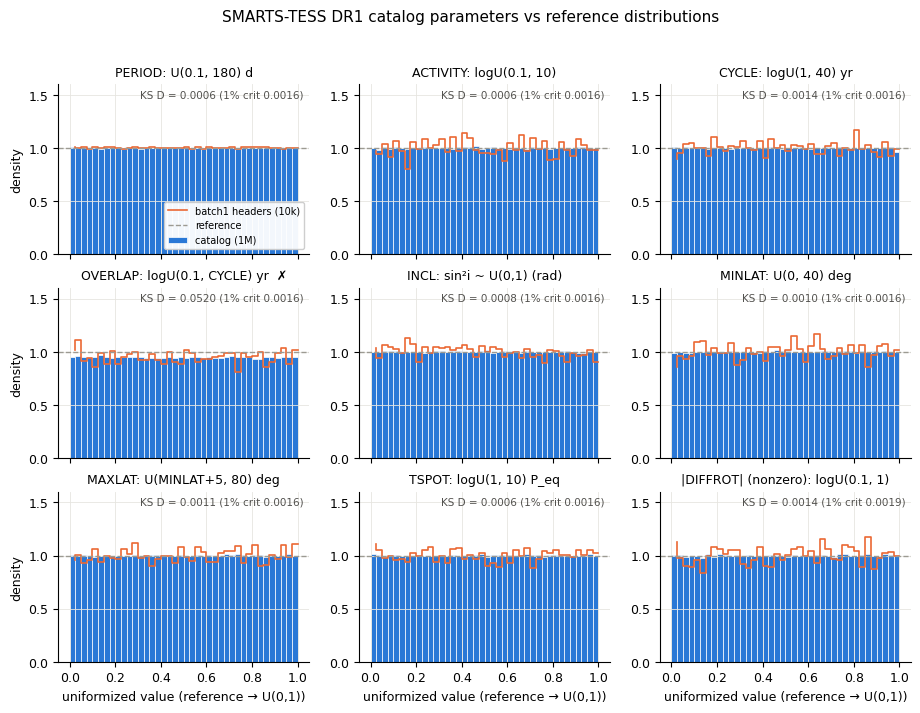

shear mix: {'solar(>0)': 0.5, 'zero': 0.25, 'anti(<0)': 0.25, '0<|shear|<0.1': 0.0}  BFLY True: 0.800587
INCL alternatives: KS uniform-in-cos i = 0.2507 ; uniform in i = 0.106


In [2]:
h = pd.read_csv(D / "param_hists.csv")
ks = inv["ks_vs_reference"]
labels = {"PERIOD": "PERIOD: U(0.1, 180) d", "ACTIVITY": "ACTIVITY: logU(0.1, 10)",
          "CYCLE": "CYCLE: logU(1, 40) yr", "OVERLAP": "OVERLAP: logU(0.1, CYCLE) yr  ✗",
          "INCL": "INCL: sin²i ~ U(0,1) (rad)", "MINLAT": "MINLAT: U(0, 40) deg",
          "MAXLAT": "MAXLAT: U(MINLAT+5, 80) deg", "TSPOT": "TSPOT: logU(1, 10) P_eq",
          "|DIFFROT|": "|DIFFROT| (nonzero): logU(0.1, 1)"}
fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), sharex=True)
for ax, (p, g) in zip(axes.flat, h.groupby("param", sort=False)):
    x = 0.5 * (g.lo + g.hi); w = (g.hi - g.lo).iloc[0]
    ax.bar(x, g.cat_frac / w, width=w, color=C1, edgecolor="white", linewidth=0.5, label="catalog (1M)")
    ax.step(g.hi, g.batch1_frac / w, where="pre", color=C2, lw=1.2, label="batch1 headers (10k)")
    ax.axhline(1, color=GRAY, ls="--", lw=1, label="reference")
    ax.set_title(labels[p], fontsize=9)
    ax.text(0.98, 0.97, f"KS D = {ks[p]['D']:.4f} (1% crit {ks[p]['D_crit_1pct']:.4f})",
            transform=ax.transAxes, fontsize=7.5, color=INK, ha="right", va="top")
    ax.set_ylim(0, 1.6)
axes[0, 0].legend(fontsize=7, loc="lower right", framealpha=0.95)
for ax in axes[-1]: ax.set_xlabel("uniformized value (reference → U(0,1))")
for ax in axes[:, 0]: ax.set_ylabel("density")
fig.suptitle("SMARTS-TESS DR1 catalog parameters vs reference distributions", fontsize=11)
fig.savefig(FIG / "param_hists.png"); plt.show()
print("shear mix:", inv["shear_mix"], " BFLY True:", inv["bfly_true_frac"])
print("INCL alternatives: KS uniform-in-cos i =", round(inv["ks_incl_uniform_cos_i"], 4),
      "; uniform in i =", round(inv["ks_incl_uniform_i"], 4))

### 1b. The one discrepancy: OVERLAP

OVERLAP is log-uniform from 0.1 yr to **max(CYCLE, √10 ≈ 3.162 yr)**, not to CYCLE.
For CYCLE < 3.16 yr, overlap can exceed the cycle length (5.2% of the corpus).

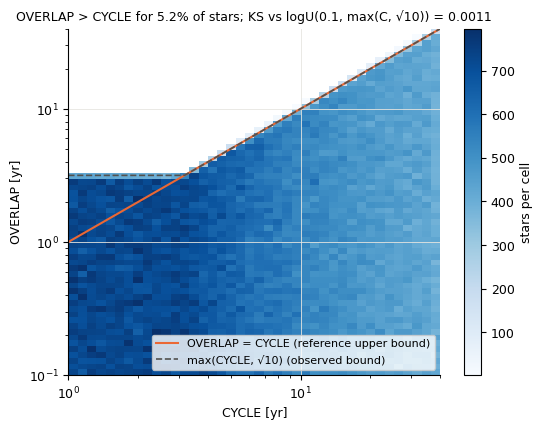

In [3]:
o = pd.read_csv(D / "overlap_cycle_hist2d.csv")
ce = np.r_[np.sort(o.c_lo.unique()), o.c_hi.max()]; oe = np.r_[np.sort(o.o_lo.unique()), o.o_hi.max()]
H = o.pivot(index="o_lo", columns="c_lo", values="n").values
fig, ax = plt.subplots(figsize=(6, 4.5))
m = ax.pcolormesh(ce, oe, np.where(H > 0, H, np.nan), cmap="Blues", shading="flat")
cc = np.geomspace(1, 40, 100)
ax.plot(cc, cc, color=C2, lw=1.5, label="OVERLAP = CYCLE (reference upper bound)")
ax.plot(cc, np.maximum(cc, np.sqrt(10)), color=INK, ls="--", lw=1.2, label="max(CYCLE, √10) (observed bound)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("CYCLE [yr]"); ax.set_ylabel("OVERLAP [yr]")
ax.legend(fontsize=8, loc="lower right"); fig.colorbar(m, ax=ax, label="stars per cell")
ax.set_title(f"OVERLAP > CYCLE for {inv['overlap']['frac_overlap_gt_cycle']:.1%} of stars; "
             f"KS vs logU(0.1, max(C, √10)) = {inv['overlap']['ks_logU_0.1_to_max_cycle_sqrt10']:.4f}", fontsize=9)
fig.savefig(FIG / "overlap_vs_cycle.png"); plt.show()

## 2. Parameter independence

Spearman rank correlation (200k random rows). Only the by-construction couplings
should be nonzero (OMEGA–PERIOD, OVERLAP–CYCLE, MAXLAT–MINLAT). SIM_ID (catalog
"Simulation Number") is included to show it carries no parameter information.

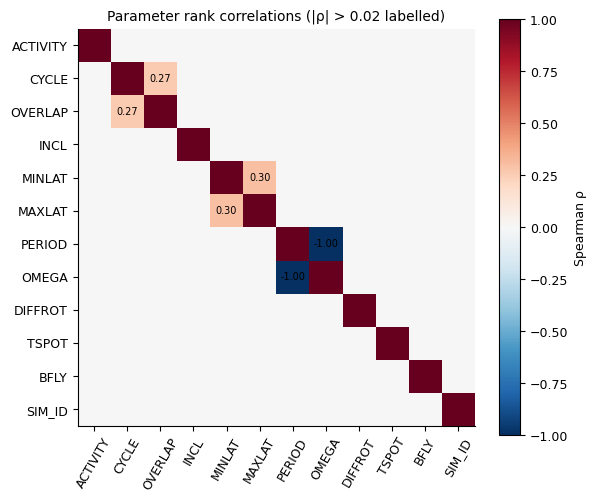

OMEGA    PERIOD    0.999999
MAXLAT   MINLAT    0.301962
OVERLAP  CYCLE     0.265188
MINLAT   PERIOD    0.004393
         OMEGA     0.004391
INCL     MINLAT    0.004100
dtype: float64


In [4]:
s = pd.read_csv(D / "spearman.csv", index_col=0)
fig, ax = plt.subplots(figsize=(6.4, 5.4))
m = ax.imshow(s.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(s)), s.columns, rotation=60); ax.set_yticks(range(len(s)), s.index)
for i in range(len(s)):
    for j in range(len(s)):
        v = s.values[i, j]
        if i != j and abs(v) > 0.02: ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(m, ax=ax, label="Spearman ρ")
ax.set_title("Parameter rank correlations (|ρ| > 0.02 labelled)", fontsize=10)
fig.savefig(FIG / "spearman.png"); plt.show()
off = s.where(~np.eye(len(s), dtype=bool)).abs().stack().sort_values(ascending=False)
print(off.drop_duplicates().head(6))

## 3. Pipeline reach

Fraction of the corpus with P_eq below B/12 (classic ≥12-cycle comb), B/3 (current
few-peak comb limit) and B/2 (ACF edge), for the full 13-sector SMARTS baseline and
for shorter contiguous coverages (applied later via `load_smarts_fits(sectors=...)`).
P_eq is uniform, so the reachable fraction is simply linear in the limit.

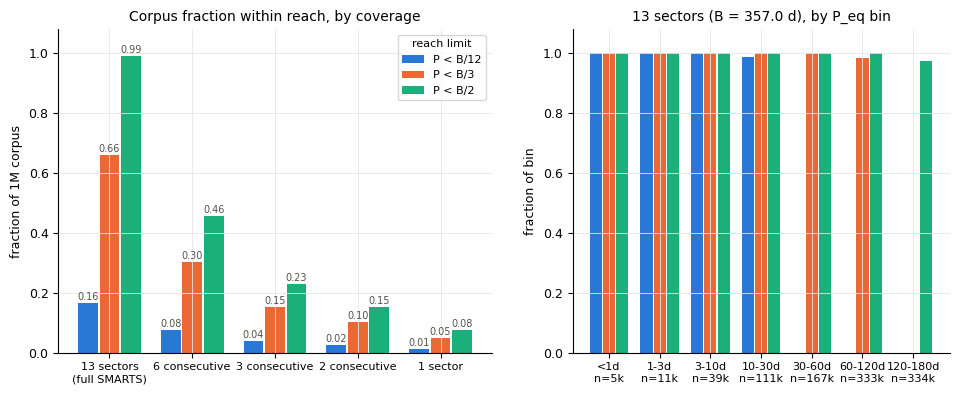

                coverage    limit  limit_d  frac_eq  frac_band_all
13 sectors (full SMARTS) P < B/12  29.7535   0.1649         0.1473
13 sectors (full SMARTS)  P < B/3 119.0138   0.6607         0.5903
13 sectors (full SMARTS)  P < B/2 178.5208   0.9917         0.8744
           6 consecutive P < B/12  13.7000   0.0759         0.0678
           6 consecutive  P < B/3  54.8000   0.3041         0.2720
           6 consecutive  P < B/2  82.2000   0.4559         0.4075
           3 consecutive P < B/12   6.8500   0.0376         0.0337
           3 consecutive  P < B/3  27.4000   0.1518         0.1358
           3 consecutive  P < B/2  41.1000   0.2281         0.2039
           2 consecutive P < B/12   4.5667   0.0250         0.0223
           2 consecutive  P < B/3  18.2667   0.1011         0.0903
           2 consecutive  P < B/2  27.4000   0.1518         0.1358
                1 sector P < B/12   2.2833   0.0121         0.0108
                1 sector  P < B/3   9.1333   0.0504         0.

In [5]:
r = pd.read_csv(D / "reach.csv")
covs = list(dict.fromkeys(r.coverage)); lims = ["P < B/12", "P < B/3", "P < B/2"]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
x = np.arange(len(covs)); w = 0.26
for k, (lim, col) in enumerate(zip(lims, (C1, C2, C3))):
    v = [r[(r.coverage == c) & (r.limit == lim) & (r.pbin == "all")].frac_eq.iloc[0] for c in covs]
    b = ax.bar(x + (k - 1) * w, v, w * 0.92, color=col, label=lim)
    for xi, vi in zip(x + (k - 1) * w, v): ax.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=7, color=INK)
ax.set_xticks(x, [c.replace(" (full SMARTS)", "\n(full SMARTS)") for c in covs], fontsize=8)
ax.set_ylabel("fraction of 1M corpus"); ax.set_ylim(0, 1.08); ax.legend(fontsize=8, title="reach limit", title_fontsize=8)
ax.set_title("Corpus fraction within reach, by coverage", fontsize=10)
ax = axes[1]
full = r[(r.coverage == covs[0]) & (r.pbin != "all")]
bins = list(dict.fromkeys(full.pbin)); xb = np.arange(len(bins))
for k, (lim, col) in enumerate(zip(lims, (C1, C2, C3))):
    v = full[full.limit == lim].set_index("pbin").loc[bins].frac_eq.values
    ax.bar(xb + (k - 1) * w, v, w * 0.92, color=col, label=lim)
n = full[full.limit == lims[0]].set_index("pbin").loc[bins].n.values
ax.set_xticks(xb, [f"{b}\nn={v/1e3:.0f}k" for b, v in zip(bins, n)], fontsize=8)
ax.set_ylabel("fraction of bin"); ax.set_ylim(0, 1.08)
ax.set_title(f"13 sectors (B = {full.baseline_d.iloc[0]:.1f} d), by P_eq bin", fontsize=10)
fig.savefig(FIG / "pipeline_reach.png"); plt.show()
print(r[r.pbin == "all"][["coverage", "limit", "limit_d", "frac_eq", "frac_band_all"]].round(4).to_string(index=False))

## 4. Differential-rotation impact

Active-band period range (P_lo, P_hi) from `evaluation.active_band_period_range`
(MINLAT/MAXLAT, butterpy sin² law), relative to P_eq. "Extends beyond ±10%": the
band reaches outside P_eq·[0.9, 1.1]. "Disjoint": the entire band is outside that
window, so P_eq itself is never a spot period (the label is not directly observable).

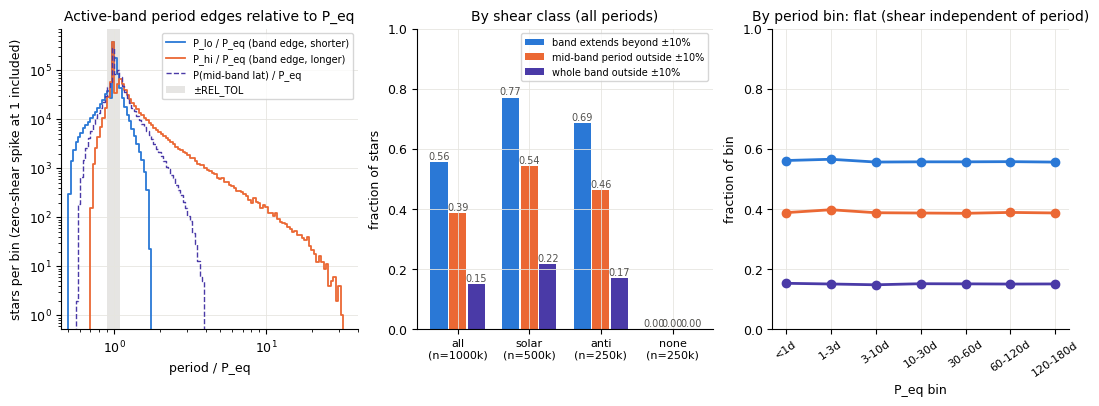

shear       n  frac_band_extends_beyond_tol  frac_band_disjoint_from_peq  frac_midlat_period_outside_tol  frac_band_width_gt_2tol  median_hi_over_eq  median_lo_over_eq
  all 1000000                        0.5564                       0.1497                          0.3867                   0.2650             1.0005             1.0000
solar  500000                        0.7698                       0.2154                          0.5421                   0.4346             1.2126             1.0339
 none  250000                        0.0000                       0.0000                          0.0000                   0.0000             1.0000             1.0000
 anti  250000                        0.6860                       0.1679                          0.4625                   0.1909             0.9683             0.8515


In [6]:
dr = pd.read_csv(D / "diffrot_bins.csv"); dh = pd.read_csv(D / "diffrot_ratio_hist.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
ax = axes[0]
xc = np.sqrt(dh.lo * dh.hi)
ax.step(dh.hi, dh.n_lo, where="pre", color=C1, lw=1.3, label="P_lo / P_eq (band edge, shorter)")
ax.step(dh.hi, dh.n_hi, where="pre", color=C2, lw=1.3, label="P_hi / P_eq (band edge, longer)")
ax.step(dh.hi, dh.n_mid, where="pre", color=C4, lw=1.0, ls="--", label="P(mid-band lat) / P_eq")
ax.axvspan(1 - evaluation.REL_TOL, 1 + evaluation.REL_TOL, color=GRAY, alpha=0.25, lw=0, label="±REL_TOL")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.45, 40); ax.set_xlabel("period / P_eq")
ax.set_ylabel("stars per bin (zero-shear spike at 1 included)"); ax.legend(fontsize=7)
ax.set_title("Active-band period edges relative to P_eq", fontsize=10)
ax = axes[1]
a = dr[dr.pbin == "all"].set_index("shear").loc[["all", "solar", "anti", "none"]]
metrics = [("frac_band_extends_beyond_tol", "band extends\nbeyond ±10%", C1),
           ("frac_midlat_period_outside_tol", "mid-band period\noutside ±10%", C2),
           ("frac_band_disjoint_from_peq", "whole band\noutside ±10%", C4)]
xs = np.arange(len(a)); w = 0.26
for k, (col, lab, c) in enumerate(metrics):
    ax.bar(xs + (k - 1) * w, a[col].values, w * 0.92, color=c, label=lab.replace("\n", " "))
    for xi, vi in zip(xs + (k - 1) * w, a[col].values): ax.text(xi, vi + 0.01, f"{vi:.2f}", ha="center", fontsize=7, color=INK)
ax.set_xticks(xs, [f"{s}\n(n={n/1e3:.0f}k)" for s, n in zip(a.index, a.n)], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("fraction of stars"); ax.legend(fontsize=7, loc="upper right")
ax.set_title("By shear class (all periods)", fontsize=10)
ax = axes[2]
b = dr[(dr.shear == "all") & (dr.pbin != "all")]
for col, lab, c in metrics:
    ax.plot(b.pbin, b[col], "o-", color=c, lw=2, ms=6, label=lab.replace("\n", " "))
ax.set_ylim(0, 1); ax.set_ylabel("fraction of bin"); ax.set_xlabel("P_eq bin")
ax.tick_params(axis="x", rotation=35); ax.set_title("By period bin: flat (shear independent of period)", fontsize=10); ax.tick_params(axis="x", labelsize=8)
fig.savefig(FIG / "diffrot_impact.png"); plt.show()
print(dr[dr.pbin == "all"].drop(columns="pbin").round(4).to_string(index=False))

## 5. Detectability proxies and joint distributions

Amplitude proxy = ACTIVITY · sin(INCL) · cos(mid-band latitude) (the rotationally
modulated part of the Claytor+2022 spot-flux model). By construction it is
independent of period, so any period-dependent detectability in the ranker's
training data comes from the noise/cadence/baseline, not the injected population.
The right panel checks the proxy against the measured light-curve amplitude in the
50-file sample.

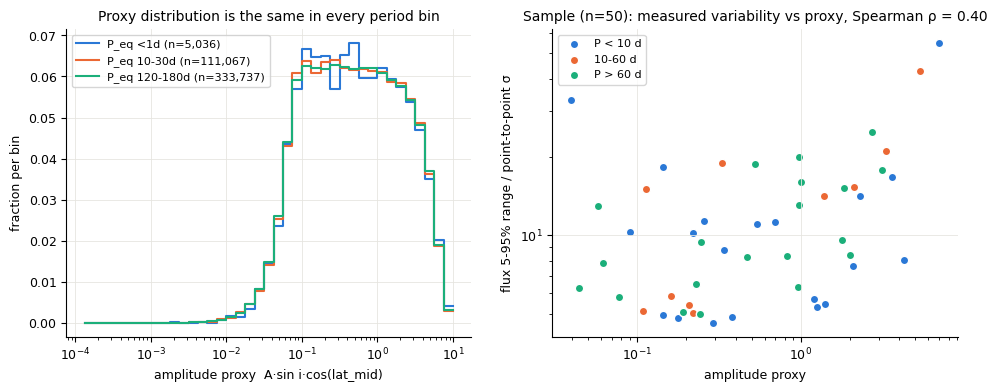

fraction of corpus with proxy < 0.05, < 0.2: 0.033 0.287
Spearman sigma_p2p vs PERIOD in sample: -0.173


In [7]:
dt = pd.read_csv(D / "detectability.csv"); sc = pd.read_csv(D / "sample_spotcheck.csv")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
ax = axes[0]
for pb, col in zip(["<1d", "10-30d", "120-180d"], (C1, C2, C3)):
    g = dt[dt.pbin == pb]; f = g.n / g.n.sum()
    ax.step(g.hi, f, where="pre", color=col, lw=1.5, label=f"P_eq {pb} (n={g.n.sum():,})")
ax.set_xscale("log"); ax.set_xlabel("amplitude proxy  A·sin i·cos(lat_mid)"); ax.set_ylabel("fraction per bin")
ax.legend(fontsize=8); ax.set_title("Proxy distribution is the same in every period bin", fontsize=10)
ax = axes[1]
prox = sc.ACTIVITY * np.sin(sc.INCL) * np.cos(np.radians(0.5 * (sc.MINLAT + sc.MAXLAT)))
ratio = sc.flux_p05_p95 / sc.sigma_p2p
for lo, hi, col, lab in [(0, 10, C1, "P < 10 d"), (10, 60, C2, "10-60 d"), (60, 200, C3, "P > 60 d")]:
    m = (sc.PERIOD >= lo) & (sc.PERIOD < hi)
    ax.scatter(prox[m], ratio[m], s=36, color=col, edgecolor="white", linewidth=1, label=lab)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("amplitude proxy")
ax.set_ylabel("flux 5-95% range / point-to-point σ")
from scipy.stats import spearmanr
rho = spearmanr(prox, ratio).statistic
ax.set_title(f"Sample (n=50): measured variability vs proxy, Spearman ρ = {rho:.2f}", fontsize=10)
ax.legend(fontsize=8)
fig.savefig(FIG / "detectability.png"); plt.show()
print("fraction of corpus with proxy < 0.05, < 0.2:",
      round(dt[dt.hi <= 0.0501].n.sum() / dt.n.sum(), 3), round(dt[dt.hi <= 0.2001].n.sum() / dt.n.sum(), 3))
print("Spearman sigma_p2p vs PERIOD in sample:", round(spearmanr(sc.sigma_p2p, sc.PERIOD).statistic, 3))

## 6. Sample light-curve gallery

One file per sampled bundle (the highest-ACTIVITY pick of its five, so the signal
is visible). Gray: raw SMARTS flux, including the linearly interpolated gap fills and
the constant end-fill; blue: what `load_smarts_fits` hands to the pipeline (gaps
re-detected, flagged orbits dropped). Inset: the file's WAVELET HDU (identical to the
catalog cube slice for all 50 files).

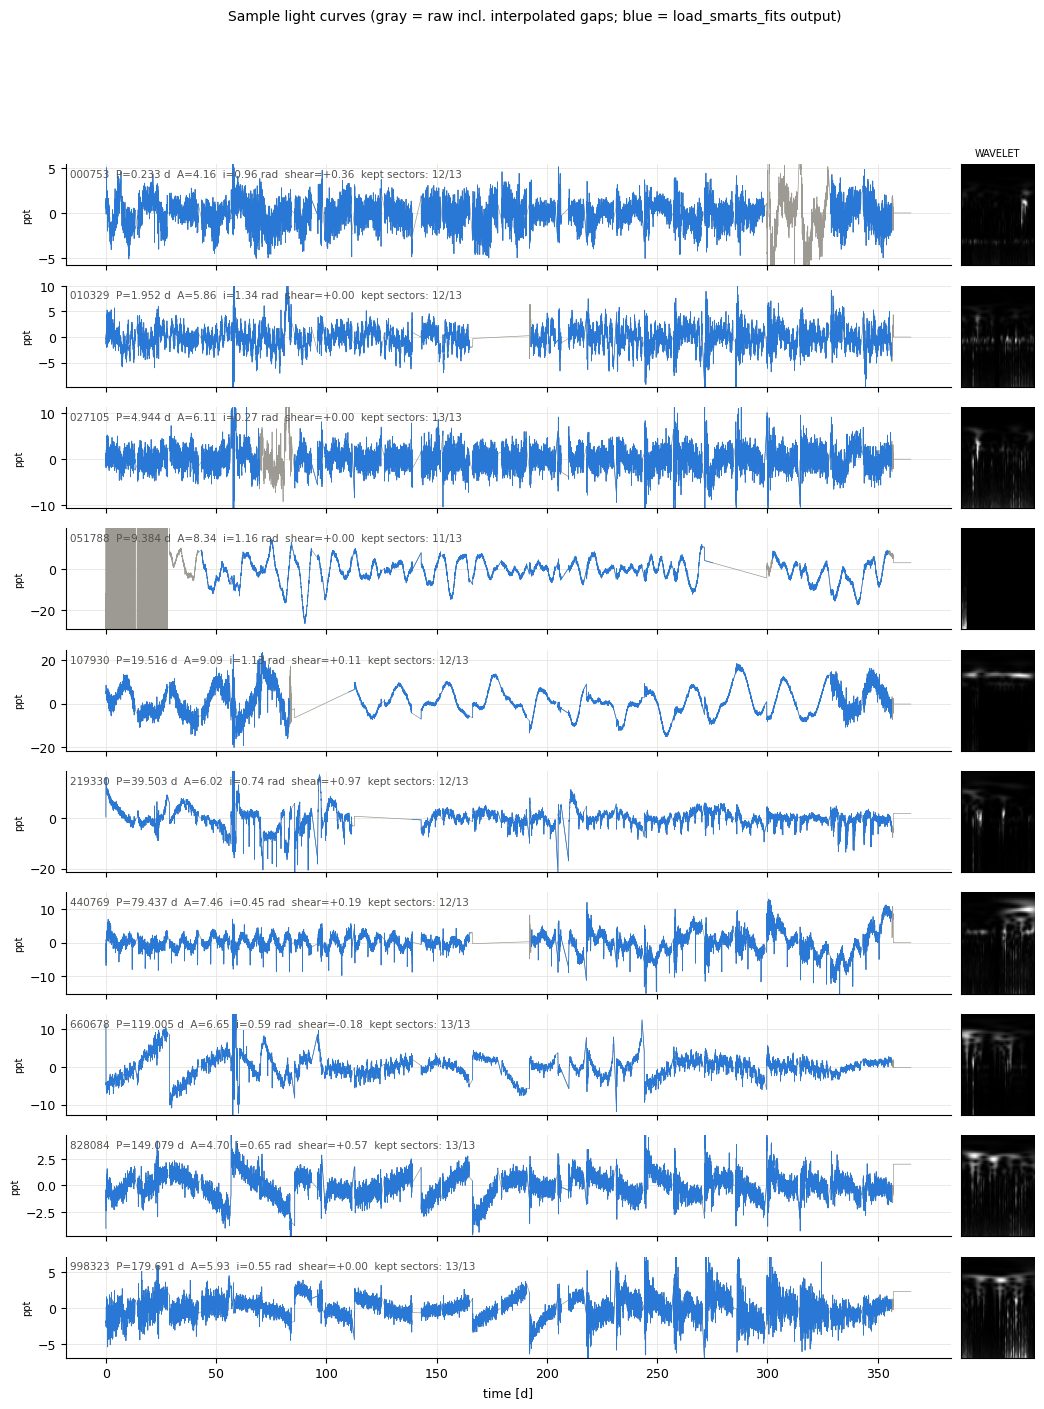

In [8]:
man = pd.read_csv(SAMPLE / "manifest.csv")
pick = man.sort_values("ACTIVITY").groupby("bundle").tail(1).sort_values("PERIOD")
fig, axs = plt.subplots(len(pick), 2, figsize=(12.5, 1.55 * len(pick)), sharex="col",
                        gridspec_kw={"width_ratios": [12, 1], "wspace": 0.02})
axes = axs[:, 0]
for k, (ax, (_, r)) in enumerate(zip(axes, pick.iterrows())):
    with fits.open(SAMPLE / r.file) as hd:
        t = hd["LIGHTCURVE"].data["time"].astype(float); f = hd["LIGHTCURVE"].data["flux"].astype(float) - 1
        wav = hd["WAVELET"].data
    lc = load_smarts_fits(SAMPLE / r.file)
    ax.plot(t, f * 1e3, color=GRAY, lw=0.5)
    ax.plot(lc.time, lc.flux * 1e3, color=C1, lw=0.5)
    ax.set_ylabel("ppt", fontsize=7)
    ax.text(0.005, 0.95, f"{r.file[-11:-5]}  P={r.PERIOD:.3f} d  A={r.ACTIVITY:.2f}  i={r.INCL:.2f} rad  "
            f"shear={r.DIFFROT:+.2f}  kept sectors: {len(lc.sectors_used)}/13",
            transform=ax.transAxes, fontsize=7.5, va="top", color=INK)
    lo, hi = np.nanpercentile(lc.flux * 1e3, [0.5, 99.5]); pad = 0.25 * (hi - lo)
    ax.set_ylim(lo - pad, hi + pad)
    ins = axs[k, 1]; ins.imshow(wav, cmap="gray", aspect="auto", origin="lower")
    ins.set_xticks([]); ins.set_yticks([]); ins.grid(False)
axs[0, 1].set_title("WAVELET", fontsize=7)
axes[-1].set_xlabel("time [d]")
fig.suptitle("Sample light curves (gray = raw incl. interpolated gaps; blue = load_smarts_fits output)", fontsize=10)
fig.savefig(FIG / "lc_gallery.png"); plt.show()

### 6b. Gap re-detection and per-orbit noise in the sample

Left: how many sectors `load_smarts_fits` keeps per file. Right: per-orbit flux
std (loader diagnostics) normalized by each file's median, with the fraction of
files where that orbit was flagged. Orbit 27 is the constant end-fill.

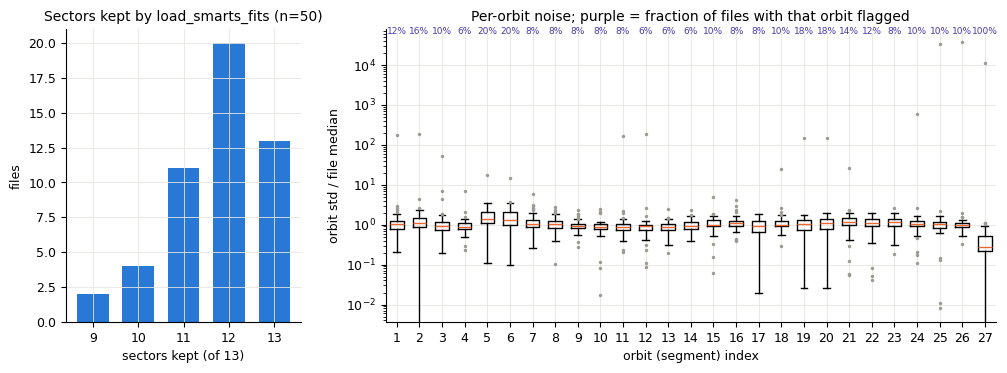

n_const_head  n_const_tail
1             381             24
              382             17
              1747             4
1382          381              2
              382              2
3             382              1
Name: count, dtype: int64
interpolated cadences per file: {'count': 50.0, 'mean': 3546.0, 'std': 1114.0, 'min': 2237.0, '25%': 2333.0, '50%': 3431.0, '75%': 4524.0, 'max': 6037.0}


In [9]:
seg = pd.read_csv(D / "sample_segments.csv")
seg["rel_std"] = seg["std"] / seg.groupby("file")["std"].transform("median")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2.6]})
ax = axes[0]
vc = sc.n_sectors_used.value_counts().sort_index()
ax.bar(vc.index, vc.values, color=C1, width=0.7); ax.set_xlabel("sectors kept (of 13)"); ax.set_ylabel("files")
ax.set_title(f"Sectors kept by load_smarts_fits (n=50)", fontsize=10)
ax = axes[1]
data = [seg[seg.orbit == o].rel_std.values for o in range(1, 28)]
ax.boxplot(data, positions=range(1, 28), widths=0.6, showfliers=True,
           flierprops=dict(marker="o", ms=2.5, mfc=GRAY, mec="none"), medianprops=dict(color=C2))
ax.set_yscale("log"); ax.set_xlabel("orbit (segment) index"); ax.set_ylabel("orbit std / file median")
flag = seg.groupby("orbit").flagged.mean()
for o, v in flag.items():
    if v > 0: ax.text(o, ax.get_ylim()[1] * 0.75, f"{v:.0%}", ha="center", fontsize=6.5, color=C4)
ax.set_title("Per-orbit noise; purple = fraction of files with that orbit flagged", fontsize=10)
fig.savefig(FIG / "gaps_and_orbit_noise.png"); plt.show()
print(sc[["n_const_head", "n_const_tail"]].value_counts())
print("interpolated cadences per file:", sc.n_interp_pts.describe().round(0).to_dict())

### 6c. Corrupt galaxy-noise orbits

Max |flux − 1| over the raw light curve for 1,050 files (the `data_subset` plus
the sample). Spots alone give at most a few percent, so excursions > 0.1 (and flux
going negative) come from corrupt orbits of the galaxy noise. Right: the worst
sample file, raw.

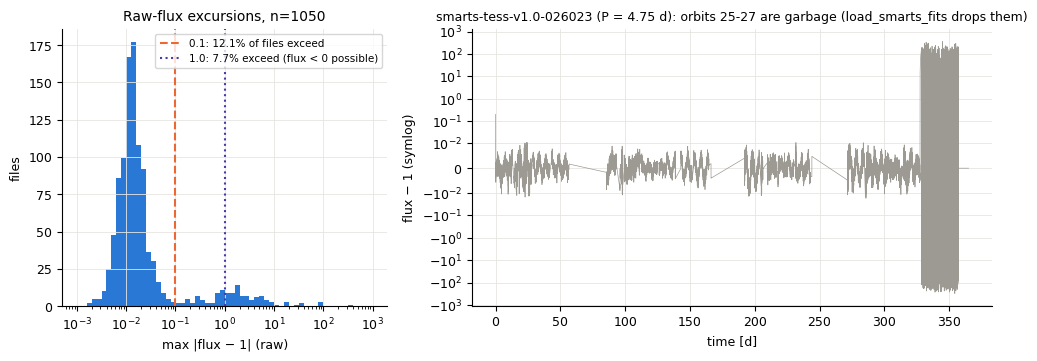

noise groups with >1 file: 229 | all-bad: 29 | mixed: 0


In [10]:
fo = pd.read_csv(D / "flux_outliers.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
edges = np.geomspace(1e-3, 1e3, 61)
ax.hist(fo.max_abs_dev, edges, color=C1)
ax.axvline(0.1, color=C2, ls="--", lw=1.5, label=f"0.1: {np.mean(fo.max_abs_dev > 0.1):.1%} of files exceed")
ax.axvline(1.0, color=C4, ls=":", lw=1.5, label=f"1.0: {np.mean(fo.max_abs_dev > 1):.1%} exceed (flux < 0 possible)")
ax.set_xscale("log"); ax.set_xlabel("max |flux − 1| (raw)"); ax.set_ylabel("files"); ax.legend(fontsize=7.5)
ax.set_title(f"Raw-flux excursions, n={len(fo)}", fontsize=10)
ax = axes[1]
with fits.open(SAMPLE / "smarts-tess-v1.0-026023.fits") as hd:
    t = hd[1].data["time"].astype(float); f = hd[1].data["flux"].astype(float)
ax.plot(t, f - 1, color=GRAY, lw=0.5); ax.set_yscale("symlog", linthresh=0.01)
ax.set_xlabel("time [d]"); ax.set_ylabel("flux − 1 (symlog)")
ax.set_title("smarts-tess-v1.0-026023 (P = 4.75 d): orbits 25-27 are garbage (load_smarts_fits drops them)", fontsize=9)
fig.savefig(FIG / "flux_outliers.png"); plt.show()
g = pd.read_csv(D / "fingerprint_groups.csv").merge(fo, on="row")
gg = g.assign(bad=g.max_abs_dev > 0.1).groupby("noise_group").bad.agg(["size", "mean"])
gg = gg[gg["size"] > 1]
print("noise groups with >1 file:", len(gg), "| all-bad:", int((gg["mean"] == 1).sum()),
      "| mixed:", int(((gg["mean"] > 0) & (gg["mean"] < 1)).sum()))

## 7. Reused noise galaxies (leakage) and the hidden train/val-test split

First-difference "noise fingerprints" of 1,050 files (the 1,000 every-100th-row
files already on the drive in `data_subset/`, plus the 50-file sample).
Same-galaxy pairs correlate at r > 0.98; everything else sits near 0. Right: for a
candidate cut on catalog "Simulation Number" (SIM_ID), the number of same-galaxy
pairs that straddle it, versus the number expected if galaxies were assigned
independently of SIM_ID.

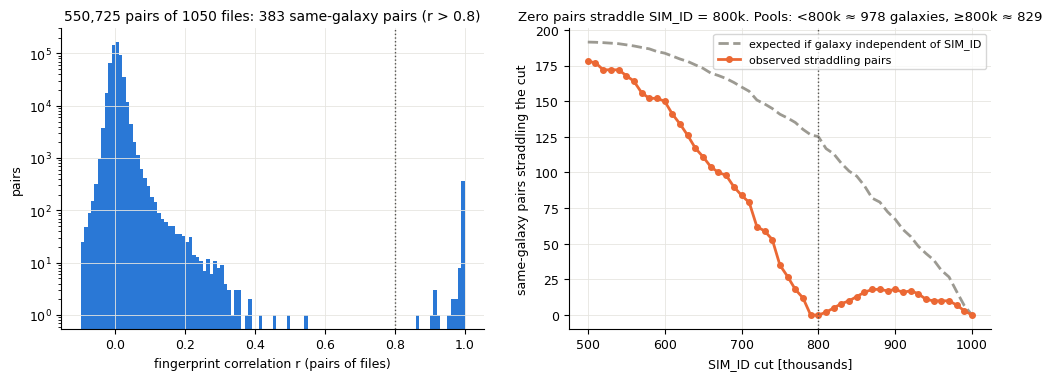

{
 "match_thresh": 0.8,
 "n_match_pairs": 383,
 "sim_lt_800k": {
  "n_files": 834,
  "n_pairs": 355,
  "n_galaxies_est": 978.4816901408451,
  "ci95": [
   881.8095788459968,
   1088.8119854370443
  ]
 },
 "sim_ge_800k": {
  "n_files": 216,
  "n_pairs": 28,
  "n_galaxies_est": 829.2857142857143,
  "ci95": [
   573.7895889499918,
   1247.998160438339
  ]
 },
 "n_noise_groups": 756,
 "group_size_counts": {
  "1": 527,
  "2": 179,
  "3": 41,
  "4": 5,
  "5": 3,
  "7": 1
 }
}
   param  median_train_gal  median_valtest_gal   ks_D
  PERIOD           90.1324             90.0218 0.0018
ACTIVITY            1.0011              0.9934 0.0021
   CYCLE            6.3243              6.2874 0.0025
 OVERLAP            0.8025              0.8032 0.0013
    INCL            0.7853              0.7840 0.0020
  MINLAT           20.0131             20.0129 0.0017
  MAXLAT           53.7978             53.8222 0.0020
 DIFFROT            0.0000              0.1003 0.0020
   TSPOT            3.1602            

In [11]:
fh = pd.read_csv(D / "fingerprint_corr_hist.csv"); fs = pd.read_csv(D / "fingerprint_split.csv")
fsum = json.load(open(D / "fingerprint_summary.json"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
ax.bar(0.5 * (fh.lo + fh.hi), fh.n_pairs, width=(fh.hi - fh.lo).iloc[0], color=C1)
ax.set_yscale("log"); ax.set_xlabel("fingerprint correlation r (pairs of files)"); ax.set_ylabel("pairs")
ax.axvline(0.8, color=INK, ls=":", lw=1)
ax.set_title(f"{fsum['n_pairs_total']:,} pairs of {fsum['n_files']} files: "
             f"{fsum['pairs_above']['0.8']} same-galaxy pairs (r > 0.8)", fontsize=10)
ax = axes[1]
ax.plot(fs.cut / 1e3, fs.expected_if_random, color=GRAY, lw=2, ls="--", label="expected if galaxy independent of SIM_ID")
ax.plot(fs.cut / 1e3, fs.cross_pairs, "o-", color=C2, lw=2, ms=4, label="observed straddling pairs")
ax.axvline(800, color=INK, ls=":", lw=1)
ax.set_xlabel("SIM_ID cut [thousands]"); ax.set_ylabel("same-galaxy pairs straddling the cut")
sp = fsum["split"]
ax.set_title(f"Zero pairs straddle SIM_ID = 800k. Pools: <800k ≈ {sp['sim_lt_800k']['n_galaxies_est']:.0f} "
             f"galaxies, ≥800k ≈ {sp['sim_ge_800k']['n_galaxies_est']:.0f}", fontsize=9.5)
ax.legend(fontsize=8)
fig.savefig(FIG / "noise_galaxy_split.png"); plt.show()
print(json.dumps(sp, indent=1))
pb = pd.read_csv(D / "t2_pool_balance.csv"); print(pb.round(4).to_string(index=False))

## 8. Bundles and T2 planning numbers

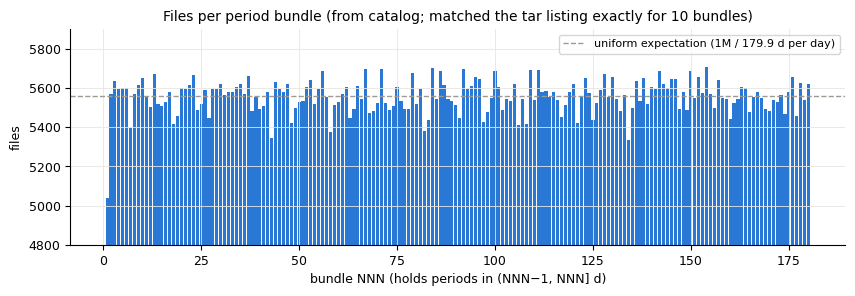

               draw  n_files  n_bundles  extracted_MB  scan_minutes
      dev_small ~42       42       31.0           6.5           3.1
   dev_medium ~1000     1001      167.0         155.7          16.7
      holdout ~3500     3500      180.0         544.3          18.0
local budget 300 MB     1929        NaN         300.0           NaN
        full corpus  1000000      180.0      155520.0          18.0
amp_tier   high    low    mid
pbin                         
<1d         325    316    343
1-3d        775    742    730
3-10d      2640   2561   2671
10-30d     7465   7387   7433
30-60d    11164  11056  11115
60-120d   22151  22242  22245
120-180d  22031  22442  22166


In [12]:
bc = pd.read_csv(D / "bundle_counts.csv"); dd = pd.read_csv(D / "t2_draft_draws.csv")
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(bc.bundle, bc.n_files, width=0.8, color=C1)
ax.axhline(1e6 / 179.9, color=GRAY, ls="--", lw=1, label="uniform expectation (1M / 179.9 d per day)")
ax.set_xlabel("bundle NNN (holds periods in (NNN−1, NNN] d)"); ax.set_ylabel("files"); ax.set_ylim(4800, 5900)
ax.legend(fontsize=8); ax.set_title("Files per period bundle (from catalog; matched the tar listing exactly for 10 bundles)", fontsize=10)
fig.savefig(FIG / "bundle_counts.png"); plt.show()
print(dd.round(1).to_string(index=False))
st = pd.read_csv(D / "t2_strata_by_pool.csv")
print(st[st.pool == "valtest_gal"].pivot_table(index="pbin", columns=["amp_tier"], values="n", aggfunc="sum")
      .loc[["<1d", "1-3d", "3-10d", "10-30d", "30-60d", "60-120d", "120-180d"]])